# Module 6: Clustering

<i>Instructor: Mackenzie Tapp</i>

# Lecture

<!--<iframe width="640" height="360" src="YOUTUBE EMBED LINK" title="YouTube video player" frameborder="0" allow="accelerometer; autoplay; clipboard-write; encrypted-media; gyroscope; picture-in-picture; web-share" referrerpolicy="strict-origin-when-cross-origin" allowfullscreen></iframe>
-->
<iframe src="https://docs.google.com/presentation/d/e/2PACX-1vQOGslBBJ2vi005LKzo2SVp_MpXe2cYx7Z3QySZPrzTAlzGCAWiXuxF26S-UtH6itJInc7xbFwwUqOh/pubembed?start=false&loop=false&delayms=3000" frameborder="0" width="960" height="569" allowfullscreen="true" mozallowfullscreen="true" webkitallowfullscreen="true"></iframe>
<!--<iframe src="GOOGLE SLIDES LINK/preview" width="640" height="480" allow="autoplay"></iframe>  
-->

# Lab


In [37]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.datasets import make_biclusters


## K Means

### A simple example

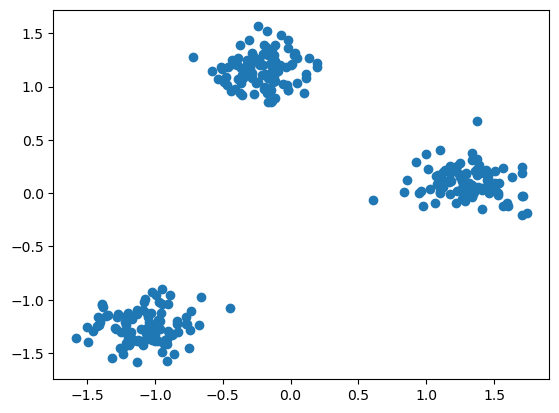

In [38]:
x, y = make_blobs(
    n_samples=300,       
    n_features=2,         
    centers=3,            
    cluster_std=1.0,      
    random_state=42
)

scaler = StandardScaler()

coordinates = scaler.fit_transform(x)
plt.scatter(coordinates[:, 0], coordinates[:, 1])

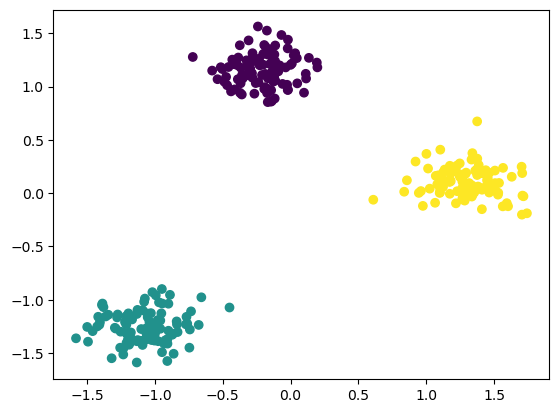

In [39]:
kmeans = KMeans(n_clusters=3, random_state=0, n_init="auto").fit(coordinates)

predicted_labels = kmeans.labels_
centroids = kmeans.cluster_centers_

plt.scatter(coordinates[:, 0], coordinates[:, 1], c=predicted_labels, cmap='viridis')


### Elbow Method Demo

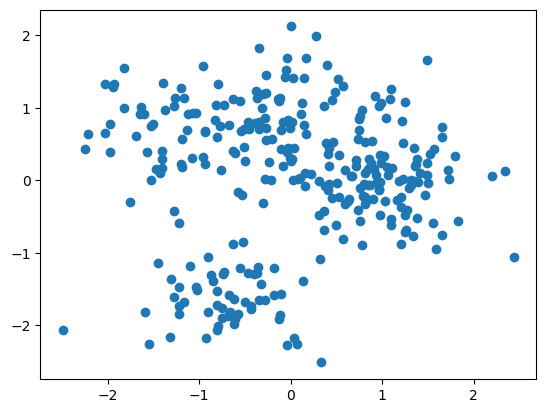

In [40]:
x, y = make_blobs(
    n_samples=300,       
    n_features=2,         
    centers=5,            
    cluster_std=3,      
    random_state=42
)

scaler = StandardScaler()

coordinates = scaler.fit_transform(x)

plt.scatter(coordinates[:,0],coordinates[:,1])

[600.0000000000002, 363.6018445834726, 167.2930562834571, 121.72102164614404, 109.27757549419385, 93.08654470322986, 80.68857395090444, 70.98920843861039, 64.33952172955853, 57.62645442434814]


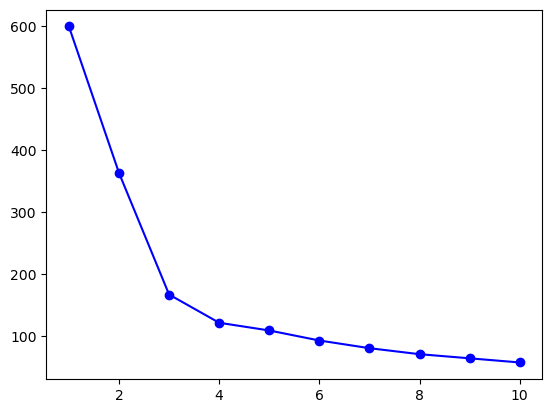

In [41]:
inertia_values = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(coordinates)
    inertia_values.append(kmeans.inertia_)

print(inertia_values)

plt.plot(k_range, inertia_values, marker='o', linestyle='-', color='b')



Text(0.5, 1.0, 'Overfitting')

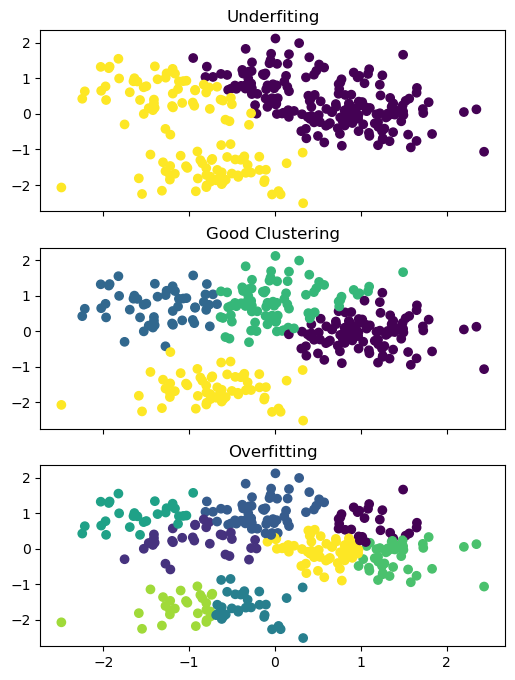

In [42]:
underfitted = KMeans(n_clusters=2, random_state=42, n_init='auto').fit(coordinates).labels_
overfitted = KMeans(n_clusters=8, random_state=42, n_init='auto').fit(coordinates).labels_
just_right = KMeans(n_clusters=4, random_state=42, n_init='auto').fit(coordinates).labels_


fig, axs = plt.subplots(3, 1, figsize=(6, 8), sharex=True)

axs[0].scatter(coordinates[:, 0], coordinates[:, 1], c=underfitted, cmap='viridis')

axs[0].set_title("Underfiting")

axs[1].scatter(coordinates[:, 0], coordinates[:, 1], c=just_right, cmap='viridis')

axs[1].set_title("Good Clustering")
axs[2].scatter(coordinates[:, 0], coordinates[:, 1], c=overfitted, cmap='viridis')

axs[2].set_title("Overfitting")

### When K Means Fails

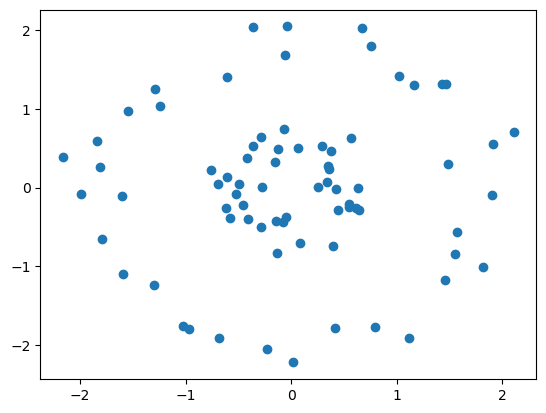

In [43]:
from sklearn.datasets import make_circles

x, y = make_circles(noise=0.1, factor=0.3, random_state=0,n_samples=75)
scaler = StandardScaler()

coordinates = scaler.fit_transform(x)


plt.scatter(coordinates[:,0], coordinates[:,1])



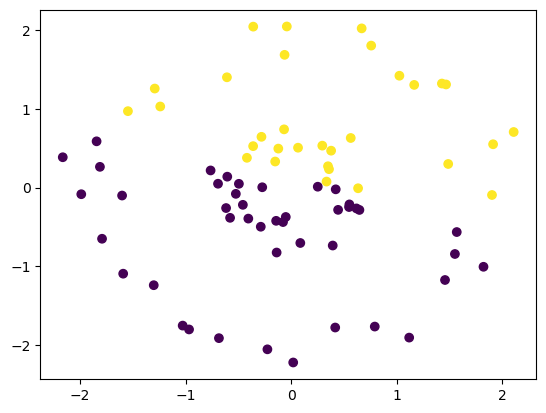

In [44]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init='auto').fit(coordinates).labels_

plt.scatter(coordinates[:, 0], coordinates[:, 1], c=kmeans, cmap='viridis')


## Hierarchical Clustering

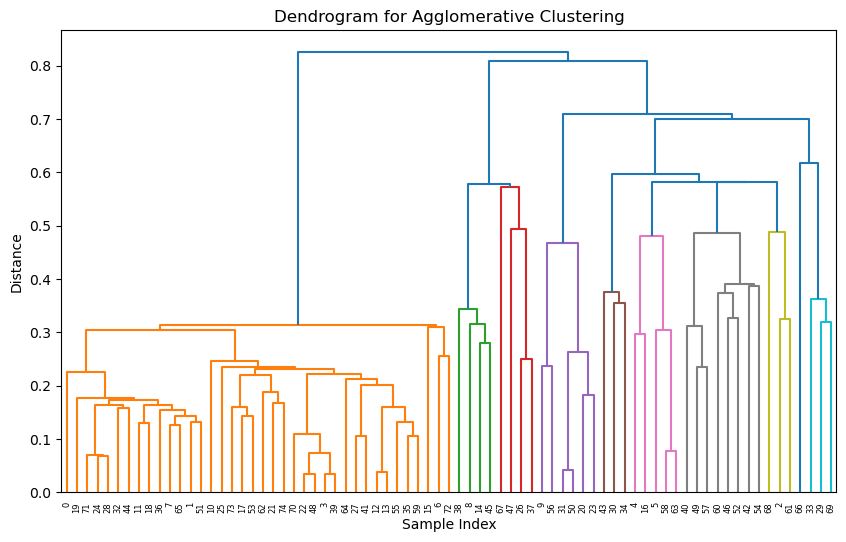

In [45]:
linked = linkage(coordinates, method='single')
plt.figure(figsize=(10, 6))
dendrogram(linked)
plt.title('Dendrogram for Agglomerative Clustering')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.show()


### Silhouette Coefficient

Two clusters: 0.19705746128411833
Three clusters: 0.2510433870708788
Five clusters: 0.35742589163359245


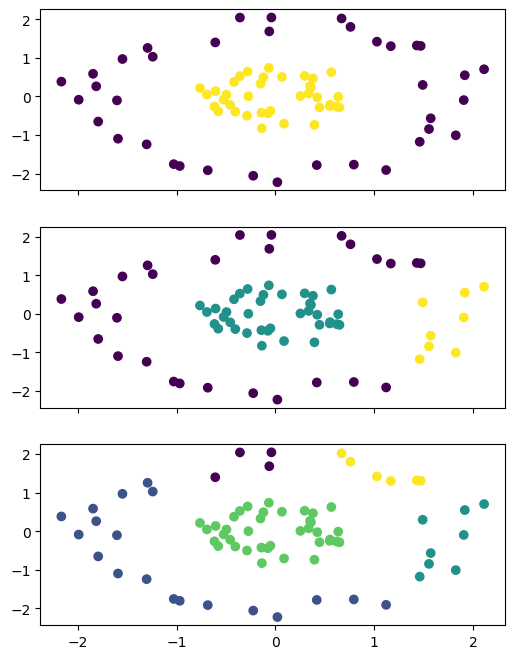

In [46]:
hc_model_2 = AgglomerativeClustering(
    linkage='single',
    n_clusters=2
)

hc_model_3 = AgglomerativeClustering(linkage= 'single', n_clusters=3)
hc_model_5 = AgglomerativeClustering(linkage= 'single', n_clusters=5)



cluster_2_labels = hc_model_2.fit_predict(coordinates)
cluster_3_labels = hc_model_3.fit_predict(coordinates)
cluster_5_labels = hc_model_5.fit_predict(coordinates)


fig, axs = plt.subplots(3, 1, figsize=(6, 8), sharex=True)


axs[0].scatter(coordinates[:, 0], coordinates[:, 1], c=cluster_2_labels, cmap='viridis')
axs[1].scatter(coordinates[:, 0], coordinates[:, 1], c=cluster_3_labels, cmap='viridis')
axs[2].scatter(coordinates[:, 0], coordinates[:, 1], c=cluster_5_labels, cmap='viridis')

print("Two clusters:",silhouette_score(coordinates, cluster_2_labels))
print("Three clusters:",silhouette_score(coordinates, cluster_3_labels))

print("Five clusters:",silhouette_score(coordinates, cluster_5_labels))

